# Reproducing the paper's results

This notebook rebuilds Table I, the turbine-bootstrap intervals and Fig. 4 of the paper from the run files
committed in `results/paper/`, and shows the evidence behind the leakage audit. It needs no GPU and no data
download, and runs in under a minute.

Setup, from the repository root:

```bash
pip install -e ".[dev]" matplotlib jupyter
jupyter notebook notebooks/reproduce.ipynb
```

To train new runs (more seeds, other settings), use the command line described in the README, then point
`RUNS` below at the new results folder.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "results").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))  # works without `pip install -e .` too

from windturbine.summary import bootstrap_difference, find_runs, plot_figure4, seed_table

RUNS = ROOT / "results" / "paper"     # committed seed-42 runs; use ROOT / "results/runs" after new training
runs = find_runs(RUNS)
print(f"{len(runs)} runs of {runs.experiment.nunique()} experiments, seeds: {sorted(int(s) for s in runs.seed.unique())}")

15 runs of 15 experiments, seeds: [42]


## Table I

CARE and its four components for every approach. With one seed per experiment the standard deviations are
empty; after a multi-seed run the same cell reports mean ± SD over seeds.

In [2]:
NAMES = {"D": "Local training (D)", "central": "Centralised comparator (pooled)",
         "central_sequential": "Centralised comparator (as in the paper)", "F1": "FedAvg (F1)",
         "F2": "Personalised (F2)", "F3_mu0": "FedProx μ = 0", "F3_mu0.001": "FedProx μ = 0.001",
         "F3_mu0.01": "FedProx μ = 0.01", "F3_mu0.1": "FedProx μ = 0.1", "F3_mu1": "FedProx μ = 1",
         "F3_mu10": "FedProx μ = 10"}
ORDER = list(NAMES)
table = seed_table(runs, ORDER)
main = table.loc[[n for n in ORDER if n in table.index]]


def fmt(row, metric, digits=3):
    sd = row[f"{metric}_sd"]
    return f"{row[f'{metric}_mean']:.{digits}f}" + ("" if pd.isna(sd) else f" ± {sd:.{digits}f}")


rows = []
for name, row in main.iterrows():
    rows.append({"Approach": NAMES[name], "Seeds": int(row.n_seeds), "CARE": fmt(row, "care"),
                 "Coverage": fmt(row, "coverage"), "Earliness": fmt(row, "earliness"),
                 "Reliability": fmt(row, "reliability"), "Accuracy": fmt(row, "accuracy"),
                 "Detected / 27": fmt(row, "detected", 0), "False alarms / 31": fmt(row, "false_alarms", 0)})
pd.DataFrame(rows).set_index("Approach")

,Seeds,CARE,Coverage,Earliness,Reliability,Accuracy,Detected / 27,False alarms / 31
Approach,,,,,,,,
Local training (D),1,0.640,0.369,0.295,0.654,0.941,14,6
Centralised comparator (as in the paper),1,0.640,0.316,0.244,0.723,0.960,12,2
FedAvg (F1),1,0.636,0.353,0.294,0.654,0.940,14,6
Personalised (F2),1,0.625,0.296,0.251,0.663,0.958,11,3
FedProx μ = 0,1,0.636,0.347,0.287,0.657,0.945,13,5
FedProx μ = 0.001,1,0.632,0.337,0.299,0.657,0.933,13,5
FedProx μ = 0.01,1,0.636,0.351,0.309,0.654,0.933,14,6
FedProx μ = 0.1,1,0.639,0.354,0.292,0.657,0.945,13,5
FedProx μ = 1,1,0.616,0.266,0.188,0.667,0.979,10,2


## The exploratory private variant (F4)

F2 with simulated secure aggregation and record-level DP-SGD. ε is computed per turbine with an RDP
accountant (δ = 10⁻⁶); the table shows the largest value over turbines.

In [3]:
private = []
for name in ["F4_sigma0", "F4_sigma0.5", "F4_sigma1", "F4_sigma2", "F4_sigma4"]:
    for path in runs.loc[runs.experiment == name, "path"]:
        privacy_file = path / "fedper_private" / "privacy.json"
        epsilon = json.loads(privacy_file.read_text())["epsilon_max"] if privacy_file.is_file() else None
        result = json.loads((path / "results.json").read_text())
        manifest = json.loads((path / "manifest.json").read_text())
        branch = next(iter(manifest["branches"].values()))
        private.append({"Noise multiplier σ": float(name.split("sigma")[1]), "Seed": int(path.name[1:]),
                        "CARE": round(result["care"], 3),
                        "ε": "–" if epsilon is None else round(epsilon, 2),
                        "Selected round": branch["selected_epoch"]})
pd.DataFrame(private).set_index("Noise multiplier σ")

,Seed,CARE,ε,Selected round
Noise multiplier σ,,,,
0.0,42,0.614,–,98
0.5,42,0.590,22.22,88
1.0,42,0.590,2.82,87
2.0,42,0.596,1.05,0
4.0,42,0.596,0.47,0


A selected round of 0 means checkpoint selection kept the untrained initial model: with σ ≥ 2 the
validation error never fell below its starting value, which is why those two runs give identical scores.

## Are the differences larger than chance?

The 58 events come from only 22 turbines, so events of one turbine are not independent. Each bootstrap
draw resamples turbines with replacement and recomputes CARE for both approaches on the same draw. A
difference counts only if its 95% interval excludes zero.

In [4]:
intervals = pd.DataFrame([bootstrap_difference(runs, name, "D", n_boot=2000)
                          for name in ORDER if name in table.index and name != "D"])
intervals.assign(approach=intervals.a.map(NAMES)).set_index("approach")[
    ["difference", "ci_low", "ci_high", "excludes_zero", "n_seeds_a"]].round(3)

,difference,ci_low,ci_high,excludes_zero,n_seeds_a
approach,,,,,
Centralised comparator (as in the paper),0.001,-0.028,0.029,False,1
FedAvg (F1),-0.004,-0.042,0.035,False,1
Personalised (F2),-0.015,-0.071,0.023,False,1
FedProx μ = 0,-0.004,-0.043,0.030,False,1
FedProx μ = 0.001,-0.008,-0.053,0.040,False,1
FedProx μ = 0.01,-0.004,-0.042,0.036,False,1
FedProx μ = 0.1,-0.001,-0.039,0.033,False,1
FedProx μ = 1,-0.024,-0.089,0.028,False,1
FedProx μ = 10,-0.050,-0.117,0.008,False,1


## Fig. 4: validation error and the FedProx sweep

(a) Validation error of the global model in each round, and of the centralised comparator in each epoch.
(b) CARE for each proximal strength μ, with D, FedAvg and the comparator as reference lines (mean ± SD over
seeds once there is more than one).

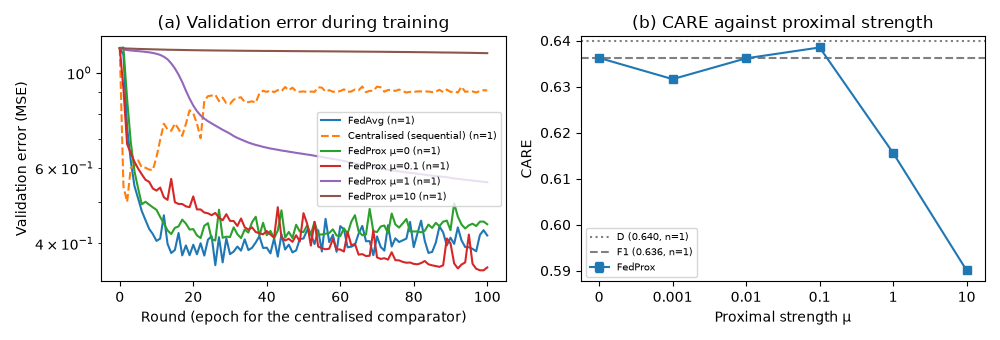

In [5]:
import tempfile

figure = Path(tempfile.mkdtemp()) / "fig4.png"
plot_figure4(RUNS, figure)
display(Image(filename=str(figure)))

Two things in panel (a) matter for reading Table I:

- **The comparator used in the paper drifted.** It trained on one turbine at a time in each epoch, so
  the model moved toward the last turbine of the epoch. Its validation error was lowest at epoch 2 and
  then rose. The `central` experiment, which shuffles minibatches across all turbines, replaces it.
- **Strong FedProx did not converge.** For μ = 10 the validation error barely moves from its starting
  value in 100 rounds, and for μ = 1 it is still falling at round 100. Their lower CARE may therefore
  reflect underfitting rather than an effect of the proximal term.

In [6]:
def curve(name, relative):
    path = runs.loc[runs.experiment == name, "path"].iloc[0] / relative
    return pd.read_csv(path).set_index("epoch")["validation_mse"]


checks = {"Comparator (paper)": curve("central_sequential", "centralized/epochs.csv"),
          "FedAvg (F1)": curve("F1", "fedavg/rounds.csv"),
          "FedProx μ = 1": curve("F3_mu1", "fedprox/rounds.csv"),
          "FedProx μ = 10": curve("F3_mu10", "fedprox/rounds.csv")}
pd.DataFrame({name: {"initial MSE": c.iloc[0], "best MSE": c.min(), "best epoch/round": int(c.idxmin()),
                     "MSE at round 100": c.iloc[-1]} for name, c in checks.items()}).T.round(3)

,initial MSE,best MSE,best epoch/round,MSE at round 100
Comparator (paper),1.141,0.500,2.0,0.910
FedAvg (F1),1.141,0.356,26.0,0.417
FedProx μ = 1,1.141,0.555,100.0,0.555
FedProx μ = 10,1.141,1.111,100.0,1.111


## Which events change between local training and FedAvg?

Both detect 14 of 27 anomaly events and raise 6 false alarms at seed 42. This shows whether they detect
the *same* events.

In [7]:
def decisions(name):
    path = runs.loc[runs.experiment == name, "path"].iloc[0]
    frame = pd.read_csv(path / "per_event.csv")
    return frame.set_index("event_id")[["asset_id", "is_anomaly", "detected"]]


both = decisions("D").rename(columns={"detected": "detected_D"}).join(
    decisions("F1")[["detected"]].rename(columns={"detected": "detected_F1"}))
changed = both[both.detected_D != both.detected_F1]
print(f"{len(changed)} of {len(both)} event decisions differ between D and F1")
changed.assign(kind=changed.is_anomaly.map({1: "anomaly", 0: "normal"})).drop(columns="is_anomaly")

6 of 58 event decisions differ between D and F1


,asset_id,detected_D,detected_F1,kind
event_id,,,,
50,12,0,1,normal
29,13,1,0,normal
70,23,1,0,anomaly
4,34,0,1,anomaly
94,34,1,0,normal
20,53,0,1,normal


## Leakage audit evidence

Summary of the audit in Section III (`results/leakage_audit/`); the full analysis is in
`notebooks/02_leakage_audit.ipynb`. Rows are matched by a hash of their raw sensor values, so the test does
not depend on the benchmark's shifted timestamps.

In [8]:
audit = json.loads((ROOT / "results" / "leakage_audit" / "evidence_summary.json").read_text())
keys = ["Within-turbine pairs tested", "Pairs with sufficient fingerprint matches", "Pairs verified as DUPLICATE",
        "TEST 5  cross-turbine false positives", "Distinct time shifts observed"]
display(pd.Series({k: audit[k] for k in keys}, name="value").to_frame())
display(Markdown("In the preliminary pooled experiment, **40,216 of 158,528 prediction rows (25.4%)** were "
                 "also in the pooled training data. Every client export used for the paper removes such rows."))

,value
Within-turbine pairs tested,64
Pairs with sufficient fingerprint matches,49
Pairs verified as DUPLICATE,49
TEST 5 cross-turbine false positives,0
Distinct time shifts observed,"['-365 days +00:00:00', '0 days 00:00:00', '36..."


In the preliminary pooled experiment, **40,216 of 158,528 prediction rows (25.4%)** were also in the pooled training data. Every client export used for the paper removes such rows.